In [1]:
# Import library yang dibutuhkan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    train_test_split,
    learning_curve
)

from sklearn.metrics import accuracy_score

In [2]:
# Memuat dataset Breast Cancer

data = load_breast_cancer()

X = data.data
y = data.target

# Melihat informasi dataset
print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Nama kelas:", data.target_names)

# Menampilkan 5 data pertama
df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y

df.head()

Jumlah data: 569
Jumlah fitur: 30
Nama kelas: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Membagi dataset menjadi training dan testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 455
Jumlah data testing: 114


In [4]:
# Bandingkan learning curve untuk max_depth berbeda

for depth in [1, 4, None]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    train_sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6),
        scoring="accuracy"
    )

    print(f"\nmax_depth={depth}")
    print(f"Train: {train_scores.mean():.3f}")
    print(f"Validation: {val_scores.mean():.3f}")


max_depth=1
Train: 0.940
Validation: 0.902

max_depth=4
Train: 0.994
Validation: 0.920

max_depth=None
Train: 1.000
Validation: 0.910


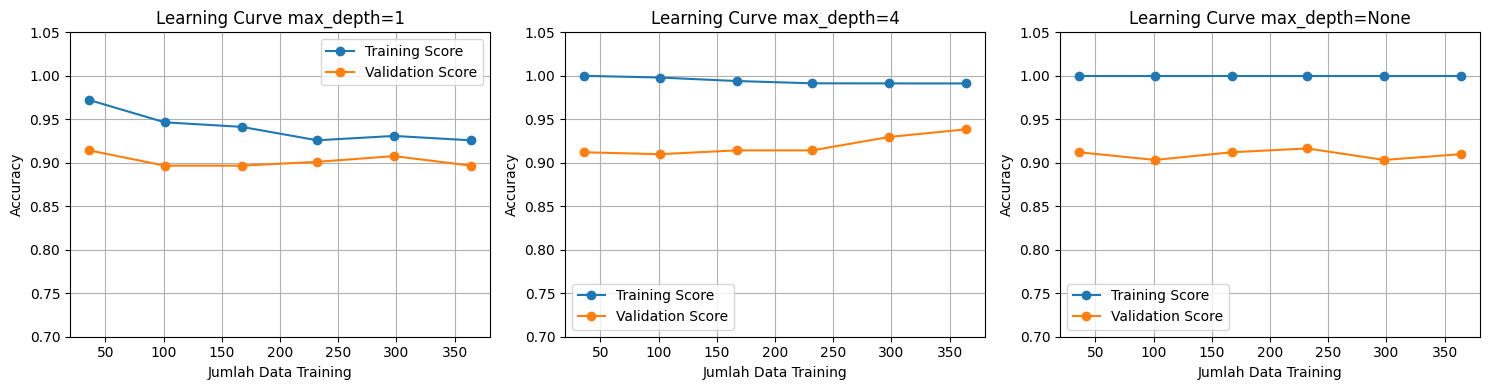

In [5]:
depths = [1, 4, None]

plt.figure(figsize=(15, 4))

for i, depth in enumerate(depths):

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    train_sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        train_sizes=np.linspace(0.1, 1.0, 6),
        scoring="accuracy"
    )

    plt.subplot(1, 3, i + 1)

    plt.plot(
        train_sizes,
        train_scores.mean(axis=1),
        marker="o",
        label="Training Score"
    )

    plt.plot(
        train_sizes,
        val_scores.mean(axis=1),
        marker="o",
        label="Validation Score"
    )

    plt.title(f"Learning Curve max_depth={depth}")
    plt.xlabel("Jumlah Data Training")
    plt.ylabel("Accuracy")
    plt.ylim(0.7, 1.05)
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

In [6]:
# Evaluasi ketiga model menggunakan data testing

for depth in [1, 4, None]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print(
        f"max_depth={depth}: "
        f"Testing Accuracy = {accuracy:.3f}"
    )

max_depth=1: Testing Accuracy = 0.921
max_depth=4: Testing Accuracy = 0.939
max_depth=None: Testing Accuracy = 0.912
